# Cellwise robust multivariate regression with cellMR

`CellMRRegression` implements cellMR of

> Centofanti, F., Hubert, M., & Rousseeuw, P. J. (2026). *Cellwise and casewise robust
> multivariate regression with inference.* arXiv:2605.08002.

It regresses several responses on many predictors when the data contain outlying cells,
outlying rows and missing values. The joint covariance of the predictors and the responses is
estimated by `CellRCov`: cellPCA (`robpy.pca.CellPCA`, Centofanti, Hubert, Raymaekers &
Rousseeuw, 2025) fits a low-dimensional subspace with cellwise and rowwise weights, and the
covariance of the residuals is added to that of the subspace. The slopes then follow as in
least squares, with a ridge penalty. New predictors are cleaned by cellPCA of the predictors
before predicting.

The implementation follows the authors' R code and reproduces its results.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from robpy.outliers.ddc import get_custom_cmap
from robpy.regression import CellMRRegression, cellboot, cellmr_tuning

## Data

We simulate 200 cases with 15 predictors driven by 3 latent factors and 2 responses that
depend linearly on the predictors. Then 4% of all cells are replaced by outliers, 5 cases are
shifted entirely, and 3% of the cells are missing. Most cases then contain at least
one outlying or missing cell.

In [2]:
rng = np.random.default_rng(1)
n, p, q = 200, 15, 2
F = rng.normal(size=(n, 3))
X = F @ rng.normal(size=(3, p)) + 0.5 * rng.normal(size=(n, p))
B_true = rng.normal(size=(p, q)) / 3
Y = 1.0 + X @ B_true + 0.5 * rng.normal(size=(n, q))

X_new = X[:20].copy()  # clean predictors of 20 cases, to evaluate predictions later

Z = np.column_stack([X, Y])
cells = rng.random(Z.shape) < 0.04
Z[cells] += rng.choice([-8.0, 8.0], cells.sum())
Z[:5] += 5.0
Z[rng.random(Z.shape) < 0.03] = np.nan
X_obs, Y_obs = Z[:, :p], Z[:, p:]
print(f"cases with an outlying or missing cell: {(cells | np.isnan(Z)).any(axis=1).mean():.0%}")

cases with an outlying or missing cell: 70%


## Tuning

cellMR has four tuning parameters: the number of components `n_components` of the joint
cellPCA, the ridge penalty, and the number of components and the shrinkage of the error
covariance of the cellPCA of the predictors, used to clean them. `cellmr_tuning` chooses them
by robust cross-validation (here on a small grid to keep it quick).

In [3]:
tuning = cellmr_tuning(
    X_obs, Y_obs, k_grid=[2, 3, 4], ridge_grid=[1e-4, 1e-2, 1.0], k_grid_X=[3], n_folds=5
)
tuning["best"], tuning["n_components_X"], tuning["shrinkage_X"]

({'n_components': 3, 'ridge': 0.0001}, 3, 0.34)

In [4]:
model = CellMRRegression(
    n_components=tuning["best"]["n_components"],
    ridge=tuning["best"]["ridge"],
    n_components_X=tuning["n_components_X"],
    shrinkage_X=tuning["shrinkage_X"],
).fit(X_obs, Y_obs)

## Comparison with least squares

Least squares can only use the complete cases and is distorted by the outlying cells.

In [5]:
complete = ~np.isnan(Z).any(axis=1)
ols = np.linalg.lstsq(
    np.column_stack([np.ones(complete.sum()), X_obs[complete]]), Y_obs[complete], rcond=None
)[0]
pd.DataFrame(
    {
        "cellMR": [np.abs(model.coef_ - B_true).mean(),
                   np.abs(model.predict(X_new) - (1.0 + X_new @ B_true)).mean()],
        "least squares": [np.abs(ols[1:] - B_true).mean(),
                          np.abs(ols[0] + X_new @ ols[1:] - (1.0 + X_new @ B_true)).mean()],
    },
    index=["mean absolute error of the slopes", "mean absolute prediction error"],
).round(3)

,cellMR,least squares
mean absolute error of the slopes,0.073,0.207
mean absolute prediction error,0.204,0.458


## Predicting with missing and outlying predictors

`predict` first shrinks outlying cells of new predictors towards their cellPCA fit and
replaces missing cells by it, so it also works when a new case has missing or outlying
values.

In [6]:
X_damaged = X_new.copy()
X_damaged[0, 3] = np.nan
X_damaged[1, 7] += 15
truth = 1.0 + X_new[:2] @ B_true
pd.DataFrame(
    np.column_stack([truth, model.predict(X_damaged)[:2]]),
    columns=["true y1", "true y2", "predicted y1", "predicted y2"],
).round(2)

,true y1,true y2,predicted y1,predicted y2
0,3.94,1.18,3.75,1.84
1,-5.07,-0.82,-4.97,-0.59


## Cell map of the residuals

The standardized cell residuals of the cellPCA of the predictors show which cells were
treated as outlying (red: higher, blue: lower than the fit). Here are the first 30 cases; the
first 5 are the shifted rows.

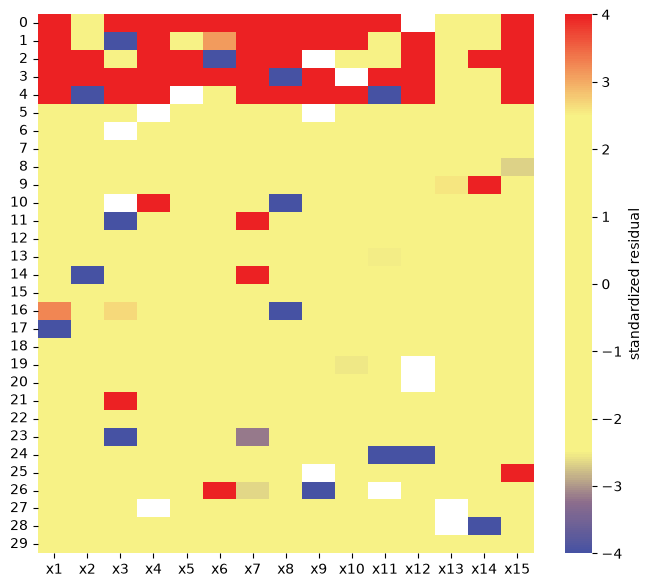

In [7]:
residuals = model.cellrcov_X_.cellpca_.standardized_residuals_[:30]
fig, ax = plt.subplots(figsize=(8, 7))
sns.heatmap(
    pd.DataFrame(residuals, columns=[f"x{j + 1}" for j in range(p)]),
    cmap=get_custom_cmap(4), vmin=-4, vmax=4, ax=ax,
    cbar_kws={"label": "standardized residual"},
)
plt.show()

## Inference with cellBoot

`cellboot` gives bootstrap confidence intervals for the coefficients (or for linear
combinations of them; Centofanti, Hubert & Rousseeuw, 2026). Each bootstrap sample uses a fast
weighted version of the estimator whose bias is removed by simulation. Here are 95% intervals
for the slopes of the first response, from 300 bootstrap samples, with the true slopes as
crosses. The intervals are wide because the 15 predictors are driven by only 3 factors, so the individual slopes are poorly determined.

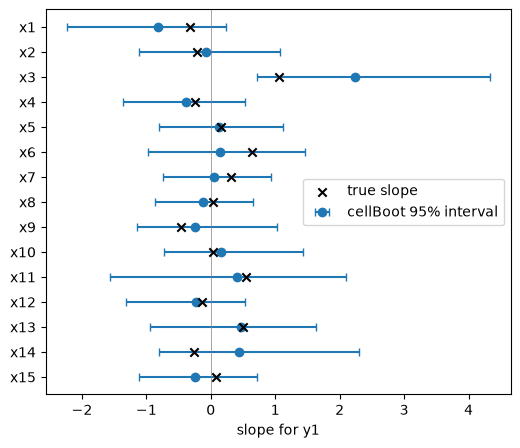

intervals that contain the true slope: 15 of 15


In [8]:
result = cellboot(
    X_obs, Y_obs, n_components=model.n_components, ridge=model.ridge, n_bootstrap=300, n_jobs=-1
)
first = slice(q, q + p)  # theta = (b0, vec(B)): the slopes of response 1 follow the intercepts
intervals = result.confidence_intervals[first]
fig, ax = plt.subplots(figsize=(6, 5))
ax.errorbar(result.coef[:, 0], np.arange(p),
            xerr=[result.coef[:, 0] - intervals[:, 0], intervals[:, 1] - result.coef[:, 0]],
            fmt="o", capsize=3, label="cellBoot 95% interval")
ax.scatter(B_true[:, 0], np.arange(p), marker="x", color="black", zorder=3, label="true slope")
ax.axvline(0, color="grey", lw=0.5)
ax.set_yticks(np.arange(p), [f"x{j + 1}" for j in range(p)])
ax.invert_yaxis()
ax.set_xlabel("slope for y1")
ax.legend()
plt.show()
covered = (intervals[:, 0] <= B_true[:, 0]) & (B_true[:, 0] <= intervals[:, 1])
print(f"intervals that contain the true slope: {covered.sum()} of {p}")